# 04 — Convolutional Neural Network (CNN)

**Input:** `../data/processed/raddar.npz`, shared code `../src/dl_utils.py`, previous results `../results/dl_step3_results.csv`
**Output:** results in `../results/`, figures in `../figures/`

**Why a CNN?** The Dense network flattens the map and loses the notion of neighbouring pixels. A CNN slides small filters over the map, so it looks at **local patterns**: the vertical line of a car, the compact spot of a drone, the horizontal micro-Doppler band of a person.

**Hypothesis (H1):** the CNN beats the Dense network (0.886) and the Random Forest (0.912), because it exploits the spatial structure of the map.

**Same protocol as step 3:** full map (11 × 61) and cropped map (11 × 13, without the stripes), 3 seeds, early stopping on the validation sessions, single evaluation on the test sessions.

**New in this step:** we look *inside* the CNN — learned filters, feature maps and **Grad-CAM** saliency maps — to check **where** it looks: at the target and its micro-Doppler, or at the stripes (shortcut).

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

sys.path.append("../src")
from dl_utils import load_data, crop_center, normalise, evaluate, plot_history, plot_confusion, CENTER_DOPPLER

import keras
from keras import layers

SEED = 42
SEEDS = [42, 7, 2026]
FIG = Path("../figures"); FIG.mkdir(parents=True, exist_ok=True)
RES = Path("../results"); RES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

D = load_data()
X, y, CLASSES = D["X"], D["y"], D["class_names"]
tr, va, te = D["train"], D["val"], D["test"]
# CNNs expect a channel dimension: (N, 11, 61) -> (N, 11, 61, 1), like a grey-scale image
INPUTS = {"full": normalise(X, tr)[..., None], "cropped": normalise(crop_center(X), tr)[..., None]}
for k, v in INPUTS.items():
    print(f"{k:8s} input shape: {v.shape}")

I0000 00:00:1794248444.190664    2084 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794248444.232165    2084 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794248445.144994    2084 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


full     input shape: (17485, 11, 61, 1)
cropped  input shape: (17485, 11, 13, 1)


## 1. Architecture
```
Input (11 × 61 × 1)
 → Conv2D(32 filters, 3×3, same) → BatchNorm → ReLU → MaxPooling (1×2)   # pool only along Doppler: keeps the 11 range bins
 → Conv2D(64 filters, 3×3, same) → BatchNorm → ReLU → MaxPooling (2×2)
 → Conv2D(64 filters, 3×3, same) → BatchNorm → ReLU                       # last convolution (used by Grad-CAM)
 → GlobalAveragePooling                                                    # one value per filter
 → Dense(64, ReLU) → Dropout(0.3) → Dense(3, softmax)
```
- **Conv2D:** each filter is a small 3×3 window of learned weights that slides over the map (a 2D convolution, like an FIR filter whose coefficients are learned). The same filter is used everywhere (**weight sharing**), so the network has far fewer parameters than the Dense network.
- **Batch normalisation:** re-centres and re-scales the outputs of each layer during training; it stabilises and speeds up learning.
- **MaxPooling:** keeps the maximum of each small block, which reduces the size and makes the network tolerant to small shifts. The first pooling only acts along Doppler because the maps have just 11 range bins.
- **GlobalAveragePooling:** averages each final feature map into one number, instead of flattening thousands of values — again far fewer parameters, less overfitting.

In [2]:
def build_cnn(input_shape, n_classes=3, dropout=0.3):
    # Functional API: same as Sequential, but gives access to inner layers (needed for Grad-CAM)
    inp = keras.Input(input_shape)
    x = layers.Conv2D(32, 3, padding="same", name="conv1")(inp)
    x = layers.ReLU()(layers.BatchNormalization()(x))
    x = layers.MaxPooling2D((1, 2))(x)
    x = layers.Conv2D(64, 3, padding="same", name="conv2")(x)
    x = layers.ReLU()(layers.BatchNormalization()(x))
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Conv2D(64, 3, padding="same", name="conv3")(x)
    x = layers.ReLU(name="last_conv")(layers.BatchNormalization()(x))
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inp, out, name="cnn")

def train(model, Xi, seed, epochs=100):
    keras.utils.set_random_seed(seed)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    t0 = time.time()
    h = model.fit(Xi[tr], y[tr], validation_data=(Xi[va], y[va]), epochs=epochs, batch_size=128,
                  callbacks=[stop], verbose=0)
    return h, time.time() - t0

build_cnn(INPUTS["full"].shape[1:]).summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 11, 61, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 11, 61, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 11, 61, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 11, 61, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 11, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 11, 30, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 30, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 11, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 15, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 5, 15, 64)      │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 5, 15, 64)      │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (ReLU)                │ (None, 5, 15, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,739 (237.26 KB)

 Trainable params: 60,419 (236.01 KB)

 Non-trainable params: 320 (1.25 KB)

## 2. Training: 2 inputs × 3 seeds

In [3]:
runs, histories, preds, models = [], {}, {}, {}
for inp, Xi in INPUTS.items():
    for s in SEEDS:
        keras.utils.set_random_seed(s)
        model = build_cnn(Xi.shape[1:])
        h, t = train(model, Xi, s)
        pv = model.predict(Xi[va], verbose=0).argmax(1)
        pt = model.predict(Xi[te], verbose=0).argmax(1)
        r = {"Input": inp, "Seed": s, "Epochs": len(h.history["loss"]),
             "Best epoch": int(np.argmin(h.history["val_loss"])) + 1, "Time (s)": t,
             "Params": model.count_params(), "Val accuracy": (pv == y[va]).mean()}
        r.update({("Test " + k): v for k, v in evaluate(y[te], pt, CLASSES).items()})
        runs.append(r)
        if s == SEEDS[0]:
            histories[inp], preds[inp], models[inp] = h, pt, model

runs = pd.DataFrame(runs)
runs.to_csv(RES / "dl_step4_cnn_runs.csv", index=False)
runs.round(3)

,Input,Seed,Epochs,Best epoch,Time (s),Params,Val accuracy,Test accuracy,Test recall Cars,Test recall Drones,Test recall People
0,full,42,19,9,147.837,60739,0.929,0.935,0.965,0.851,0.972
1,full,7,19,9,156.239,60739,0.960,0.948,0.892,0.967,0.981
2,full,2026,19,9,147.693,60739,0.945,0.941,0.955,0.877,0.977
3,cropped,42,14,4,32.441,60739,0.939,0.919,0.824,0.948,0.979
4,cropped,7,15,5,35.237,60739,0.948,0.940,0.871,0.960,0.985
5,cropped,2026,13,3,29.928,60739,0.928,0.910,0.771,0.988,0.971


## 3. Learning curves (seed 42)

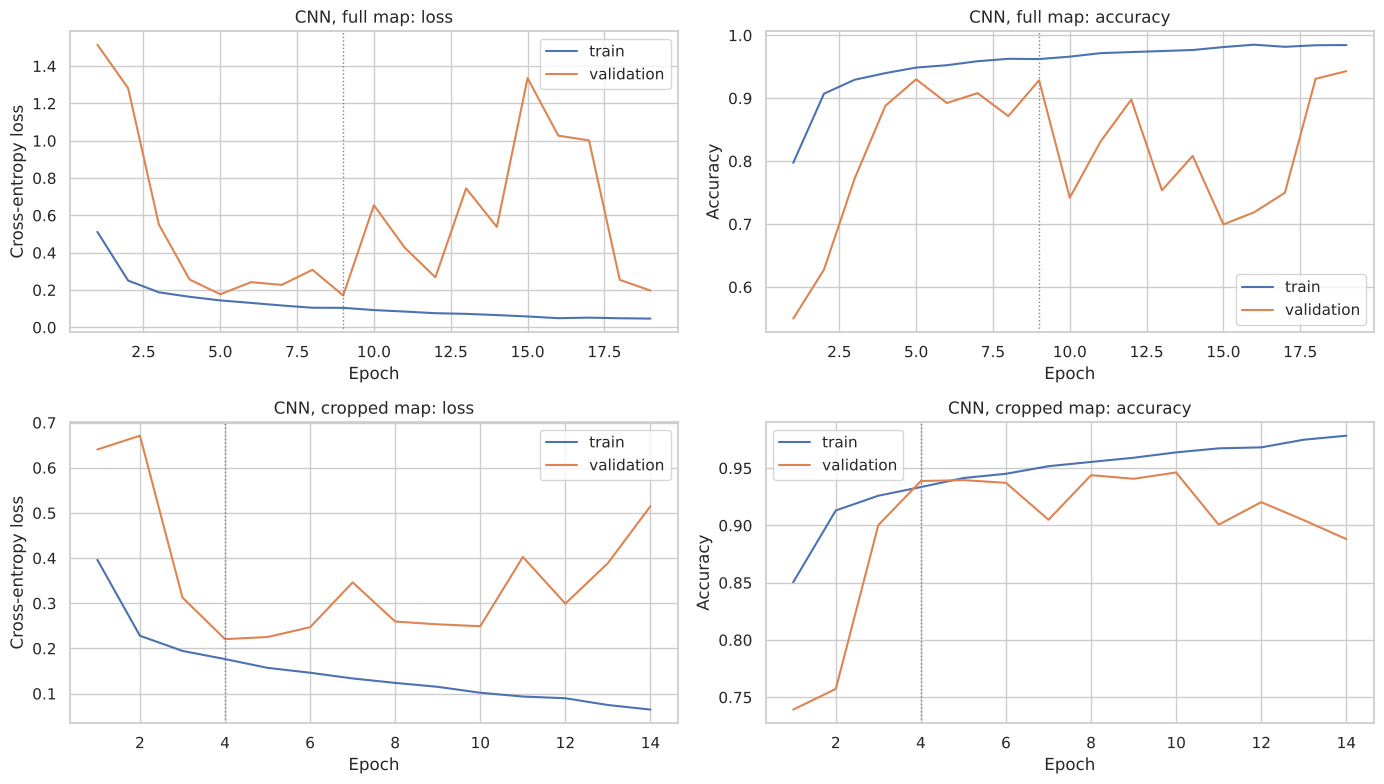

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for row, inp in enumerate(["full", "cropped"]):
    plot_history(histories[inp], f"CNN, {inp} map", axes[row, 0], axes[row, 1])
plt.tight_layout(); plt.savefig(FIG / "dl_12_cnn_learning_curves.png", dpi=200); plt.show()

## 4. Comparison with all previous models (test sessions)

In [5]:
cols = ["Val accuracy", "Test accuracy"] + [f"Test recall {c}" for c in CLASSES]
prev = pd.read_csv(RES / "dl_step3_results.csv")
agg = runs.groupby("Input")[cols].agg(["mean", "std"])
new = []
for inp in ["full", "cropped"]:
    r = {"Model": "CNN", "Input": f"{inp} map"}
    for c in cols:
        r[c] = agg.loc[inp, (c, "mean")]
    r["Test accuracy std (3 seeds)"] = agg.loc[inp, ("Test accuracy", "std")]
    r["Params"] = int(runs.loc[runs.Input == inp, "Params"].iloc[0])
    new.append(r)
allres = pd.concat([prev, pd.DataFrame(new)], ignore_index=True)
allres.to_csv(RES / "dl_results_all.csv", index=False)
allres.round(3)

,Model,Input,Val accuracy,Test accuracy,Test recall Cars,Test recall Drones,Test recall People,Test accuracy std (3 seeds),Params
0,Logistic regression,3 physical features,0.916,0.845,0.681,0.899,0.947,NaN,NaN
1,Random Forest,3 physical features,0.916,0.861,0.759,0.842,0.962,NaN,NaN
2,Random Forest,full map (raw values),0.917,0.912,0.849,0.960,0.930,NaN,NaN
3,Random Forest,cropped map (raw values),0.918,0.909,0.837,0.954,0.938,NaN,NaN
4,Dense (MLP),full map,0.927,0.886,0.824,0.911,0.920,0.009,205315.0
5,Dense (MLP),cropped map,0.921,0.887,0.798,0.908,0.948,0.008,70147.0
6,CNN,full map,0.945,0.941,0.938,0.898,0.977,0.006,60739.0
7,CNN,cropped map,0.938,0.923,0.822,0.965,0.978,0.015,60739.0


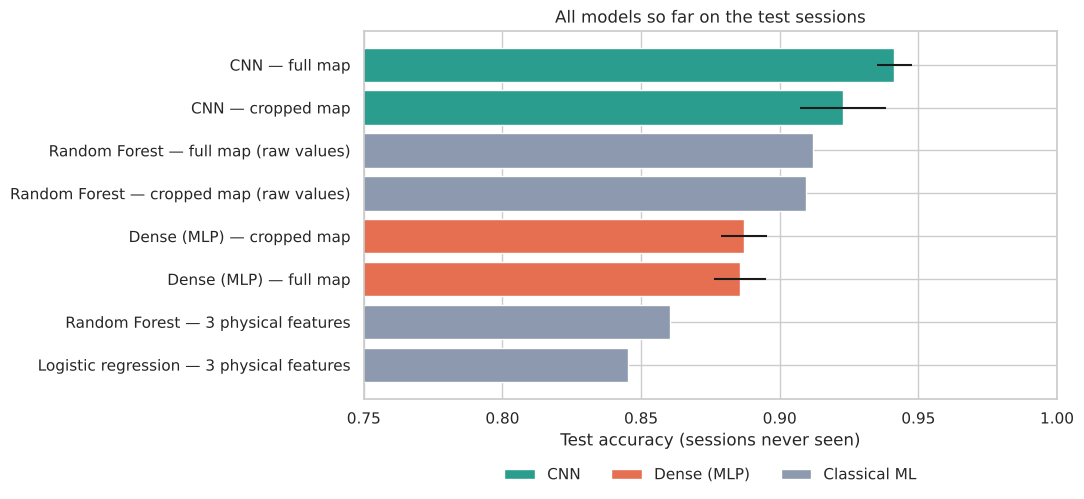

In [6]:
fig, ax = plt.subplots(figsize=(11, 5.2))
lab = allres["Model"] + " — " + allres["Input"]
order = allres["Test accuracy"].sort_values().index
colours = {"CNN": "#2a9d8f", "Dense (MLP)": "#e76f51"}
ax.barh(lab[order], allres.loc[order, "Test accuracy"],
        xerr=allres.loc[order, "Test accuracy std (3 seeds)"].fillna(0),
        color=[colours.get(m, "#8d99ae") for m in allres.loc[order, "Model"]])
ax.set(xlabel="Test accuracy (sessions never seen)", xlim=(0.75, 1.0), title="All models so far on the test sessions")
for m, c in [("CNN", "#2a9d8f"), ("Dense (MLP)", "#e76f51"), ("Classical ML", "#8d99ae")]:
    ax.barh(0, 0, color=c, label=m)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
plt.tight_layout(); plt.savefig(FIG / "dl_13_models_comparison.png", dpi=200); plt.show()

## 5. Confusion matrices (seed 42)

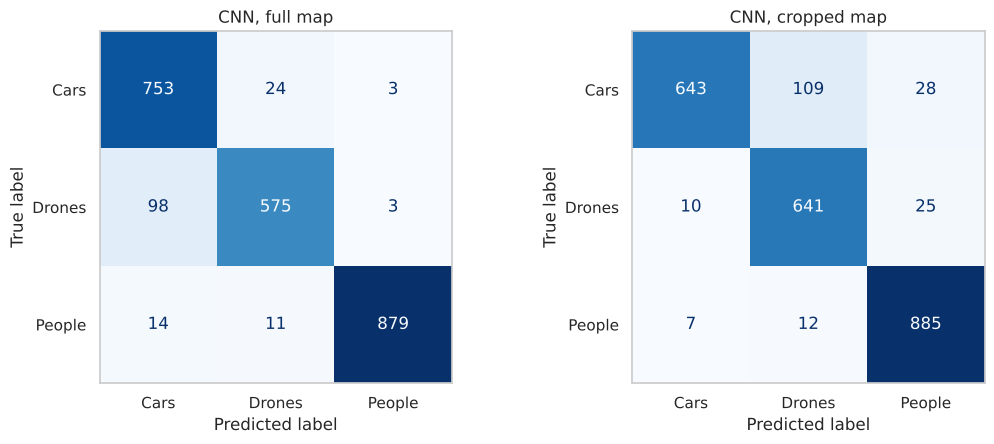

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, inp in zip(axes, ["full", "cropped"]):
    plot_confusion(y[te], preds[inp], CLASSES, f"CNN, {inp} map", ax)
plt.tight_layout(); plt.savefig(FIG / "dl_14_cnn_confusion.png", dpi=200); plt.show()

## 6. Inside the CNN: learned filters and feature maps
- **Filters:** the 32 learned 3×3 kernels of the first convolution (red = positive weight, blue = negative). Each one detects a small local pattern (an edge, a vertical or horizontal line, a spot).
- **Feature maps:** the output of some of these filters for one example map of each class — where in the map each pattern is found.

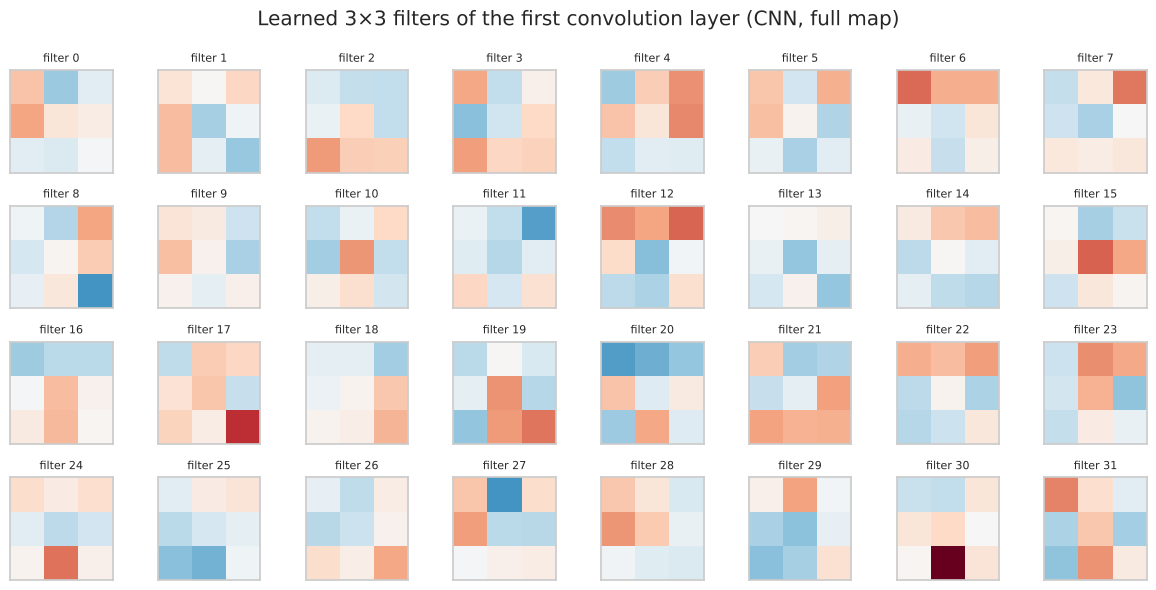

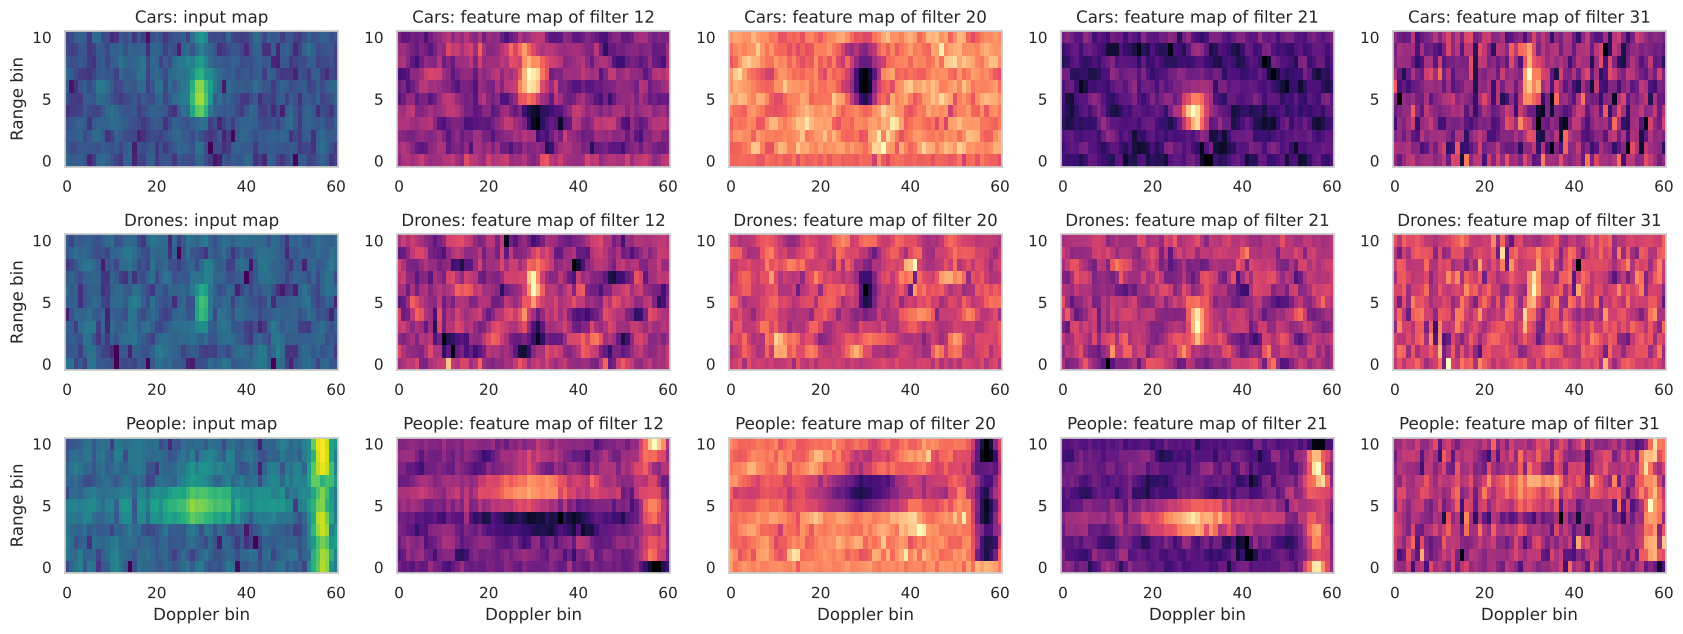

In [8]:
m = models["full"]
W = m.get_layer("conv1").get_weights()[0][:, :, 0, :]          # (3, 3, 32)
fig, axes = plt.subplots(4, 8, figsize=(12, 6))
vmax = np.abs(W).max()
for k, ax in enumerate(axes.ravel()):
    ax.imshow(W[:, :, k], cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set(xticks=[], yticks=[], title=f"filter {k}"); ax.title.set_fontsize(8)
fig.suptitle("Learned 3×3 filters of the first convolution layer (CNN, full map)")
plt.tight_layout(); plt.savefig(FIG / "dl_15a_cnn_filters.png", dpi=200); plt.show()

feat_model = keras.Model(m.inputs, m.get_layer("conv1").output)
rng = np.random.default_rng(SEED)
ex = [rng.choice(te[(y[te] == i) & (preds["full"] == i)]) for i in range(3)]
fmaps = feat_model.predict(INPUTS["full"][ex], verbose=0)            # (3, 11, 61, 32)
strongest = np.argsort(-np.abs(W).sum(axis=(0, 1)))[:4]
fig, axes = plt.subplots(3, 5, figsize=(17, 6.5))
for r, (k, i) in enumerate(zip(ex, range(3))):
    axes[r, 0].imshow(X[k], aspect="auto", origin="lower", cmap="viridis", vmin=-135, vmax=-60)
    axes[r, 0].set(title=f"{CLASSES[i]}: input map", ylabel="Range bin")
    for c, f in enumerate(strongest, start=1):
        axes[r, c].imshow(fmaps[r, :, :, f], aspect="auto", origin="lower", cmap="magma")
        axes[r, c].set(title=f"{CLASSES[i]}: feature map of filter {f}")
for ax in axes.ravel(): ax.grid(False)
for ax in axes[-1]: ax.set_xlabel("Doppler bin")
plt.tight_layout(); plt.savefig(FIG / "dl_15b_cnn_feature_maps.png", dpi=200); plt.show()

## 7. Where does the CNN look? Grad-CAM
**Grad-CAM** computes, for one map and one class, how much each region of the last convolution layer contributes to the predicted class (gradient of the class score with respect to the feature maps, weighted and summed, keeping only the positive part). Bright = regions that push the network towards its decision.

**Shortcut test:** for each correctly classified test map we measure the **share of the Grad-CAM attention that falls outside the central Doppler region** (bins 24–36, where the target is). If the CNN relied on the stripes, People maps with a stripe would put a large share of their attention outside the centre.

*Reference:* the central region covers 13 of the 61 Doppler bins, so a CNN looking **uniformly** everywhere would put 48/61 ≈ 79% of its attention outside the centre. Values well below 79% mean the attention is concentrated on the target.

In [9]:
def grad_cam(model, Xb, class_idx, layer="last_conv"):
    grad_model = keras.Model(model.inputs, [model.get_layer(layer).output, model.output])
    Xb = tf.convert_to_tensor(Xb)
    with tf.GradientTape() as tape:
        conv, out = grad_model(Xb, training=False)
        score = tf.gather(out, class_idx, axis=1, batch_dims=1)
    grads = tape.gradient(score, conv)
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(weights * conv, axis=-1))[..., None]
    cam = tf.image.resize(cam, Xb.shape[1:3]).numpy()[..., 0]     # back to 11 x 61
    return cam / (cam.reshape(len(cam), -1).max(1)[:, None, None] + 1e-9)

ok = te[preds["full"] == y[te]]
cams = np.concatenate([grad_cam(models["full"], INPUTS["full"][b], y[b].astype("int32"))
                       for b in np.array_split(ok, 10)])

noise = np.median(X.reshape(len(X), -1), axis=1)
stripe = ((X.min(axis=1) - noise[:, None])[:, np.r_[0:24, 37:61]] > 10).any(axis=1)
outside = 1 - cams[:, :, CENTER_DOPPLER].sum(axis=(1, 2)) / cams.sum(axis=(1, 2))
att = pd.DataFrame({"class": np.array(CLASSES)[y[ok]], "stripe": stripe[ok], "outside_share": outside})
att_table = att.groupby(["class", "stripe"])["outside_share"].agg(["count", "mean"]).round(3)
att_table.columns = ["Maps", "Mean share of attention outside the centre"]
att_table

Maps  Mean share of attention outside the centre
class  stripe                                                  
Cars   False    751                                       0.452
       True       2                                       0.768
Drones False    575                                       0.581
People False    128                                       0.491
       True     751                                       0.744

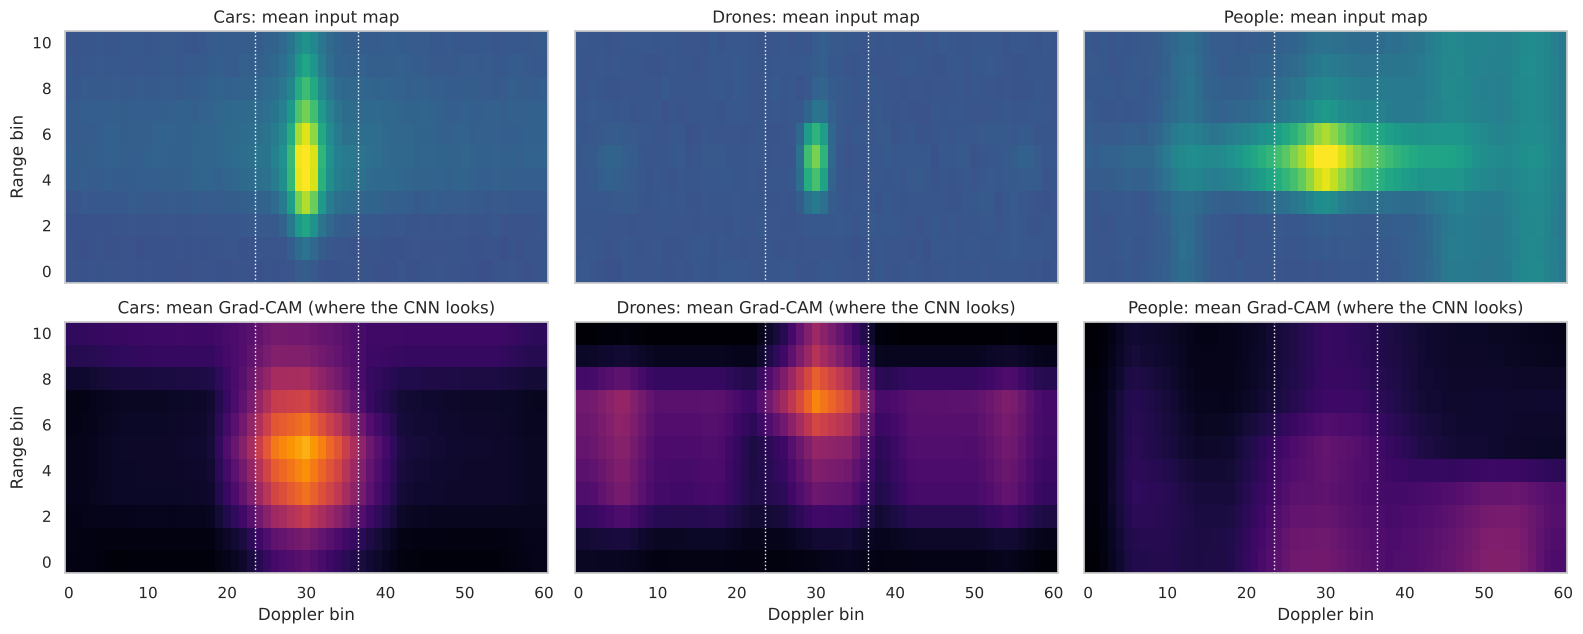

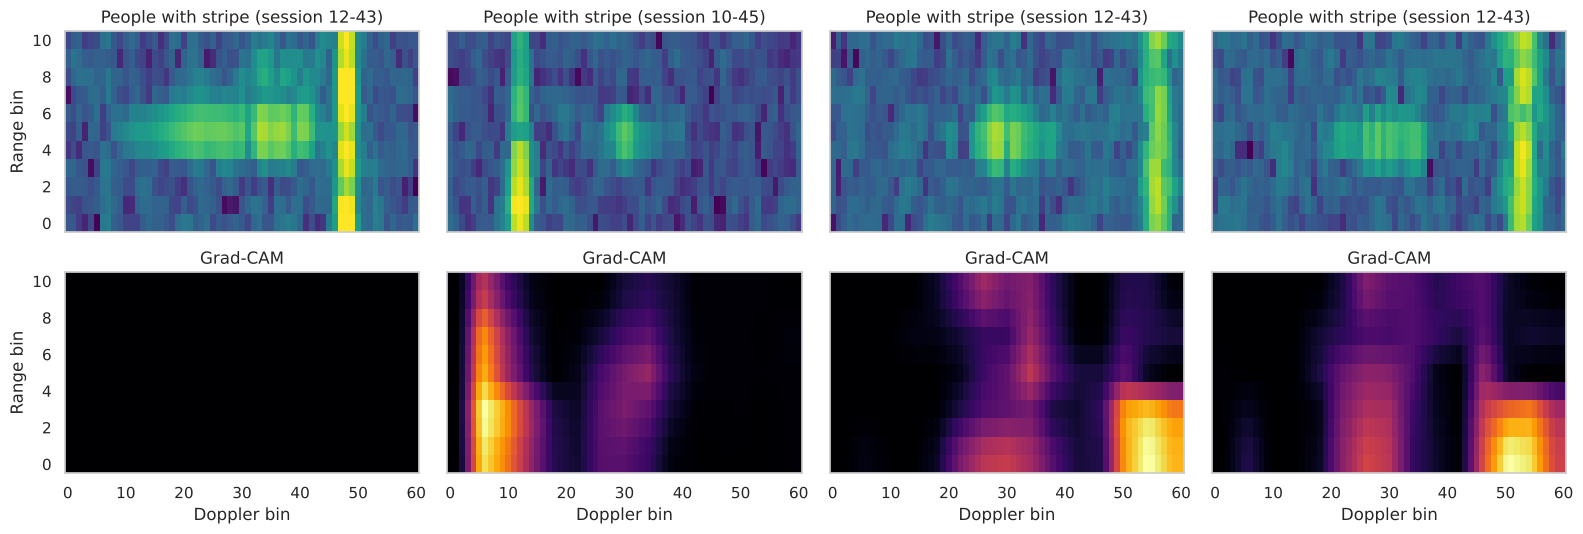

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 6.5), sharex=True, sharey=True)
for j, c in enumerate(CLASSES):
    sel = y[ok] == j
    axes[0, j].imshow(X[ok][sel].mean(0), aspect="auto", origin="lower", cmap="viridis", vmin=-125, vmax=-85)
    axes[0, j].set_title(f"{c}: mean input map")
    axes[1, j].imshow(cams[sel].mean(0), aspect="auto", origin="lower", cmap="inferno", vmin=0, vmax=1)
    axes[1, j].set_title(f"{c}: mean Grad-CAM (where the CNN looks)")
    for r in range(2):
        axes[r, j].axvline(CENTER_DOPPLER.start - 0.5, color="w", ls=":", lw=1)
        axes[r, j].axvline(CENTER_DOPPLER.stop - 0.5, color="w", ls=":", lw=1)
        axes[r, j].grid(False)
    axes[1, j].set_xlabel("Doppler bin")
axes[0, 0].set_ylabel("Range bin"); axes[1, 0].set_ylabel("Range bin")
plt.tight_layout(); plt.savefig(FIG / "dl_16a_cnn_gradcam_mean.png", dpi=200); plt.show()

ppl_stripe = ok[(y[ok] == CLASSES.index("People")) & stripe[ok]]
ex = np.random.default_rng(SEED).choice(ppl_stripe, 4, replace=False)
cex = grad_cam(models["full"], INPUTS["full"][ex], y[ex].astype("int32"))
fig, axes = plt.subplots(2, 4, figsize=(16, 5.5), sharex=True, sharey=True)
for c, k in enumerate(ex):
    axes[0, c].imshow(X[k], aspect="auto", origin="lower", cmap="viridis", vmin=-135, vmax=-60)
    axes[0, c].set_title(f"People with stripe (session {D['sessions'][k]})")
    axes[1, c].imshow(cex[c], aspect="auto", origin="lower", cmap="inferno", vmin=0, vmax=1)
    axes[1, c].set_title("Grad-CAM"); axes[1, c].set_xlabel("Doppler bin")
for ax in axes.ravel(): ax.grid(False)
axes[0, 0].set_ylabel("Range bin"); axes[1, 0].set_ylabel("Range bin")
plt.tight_layout(); plt.savefig(FIG / "dl_16b_cnn_gradcam_people_stripes.png", dpi=200); plt.show()

## 8. Conclusions
*(to be written in the report from the outputs above)*